# Building a Mini GPT from Scratch

A character-level, **decoder-only Transformer (GPT-style)** implemented entirely in PyTorch and trained on a small Shakespeare corpus (the *Romeo and Juliet* balcony scene).

**What this notebook does**
1. **Data preparation** — character-level tokenization + a sliding-window autoregressive dataset (sequence length = 128).
2. **Architecture** — multi-head masked self-attention (4 heads), a Transformer decoder block, and a 2-layer GPT, all built by hand.
3. **Training** — Adam optimizer, cross-entropy loss, 8 epochs, with a loss-vs-epoch curve.
4. **Sampling** — greedy, temperature, and top-k decoding.
5. **Analysis** — a comparison of the three decoding strategies.

**Constraints honoured:** everything is built from `nn.Linear`, `nn.LayerNorm`, `nn.GELU`, `nn.Embedding` and standard tensor ops. **No** `nn.Transformer`, **no** `nn.MultiheadAttention`, **no** HuggingFace models are used.

```text
text -> char IDs -> token + positional embeddings -> N x (masked MHA -> FFN)
     -> LayerNorm -> linear head -> next-char logits -> loss / generation
```

## Setup

Imports, device selection, and a `set_seed` helper for reproducibility. The model is small enough to train comfortably on CPU; it will use a GPU automatically if one is present.

In [1]:
import math
import random
import numpy as np

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"


def set_seed(seed: int = 42):
    """Seed Python, NumPy and PyTorch so runs are reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(42)
print("Using device:", device)

Using device: cpu


# Part 1 — Data Preparation

## 1.1 Character-Level Tokenization

A language model works on integers, not raw text. At the **character level** we:

1. collect the set of unique characters in the corpus (this is the *vocabulary*),
2. map every character to an integer id (`char_to_idx`) and back (`idx_to_char`),
3. encode the whole corpus into a 1-D tensor of ids.

Character-level tokenization keeps the vocabulary tiny, at the cost of longer sequences than word/subword tokenization would produce.

In [2]:
# Load the corpus (the Romeo & Juliet balcony scene).
with open("shakespeare.txt", "r", encoding="utf-8") as f:
    text = f.read()

# 1) Unique characters, sorted for a deterministic ordering -> the vocabulary.
chars = sorted(list(set(text)))
vocab_size = len(chars)

# 2) Two lookup tables: character <-> integer id.
char_to_idx = {ch: i for i, ch in enumerate(chars)}
idx_to_char = {i: ch for ch, i in char_to_idx.items()}


def encode(s: str):
    """String -> list of integer ids."""
    return [char_to_idx[c] for c in s]


def decode(ids):
    """Iterable of ids -> string."""
    return "".join(idx_to_char[int(i)] for i in ids)


# 3) Encode the entire corpus into one long tensor of token ids.
data = torch.tensor(encode(text), dtype=torch.long)

print(f"Total characters in corpus : {len(text)}")
print(f"Vocabulary size            : {vocab_size}")
print(f"Vocabulary                 : {''.join(chars)!r}")
print(f"Encoded data tensor shape  : {tuple(data.shape)}")

Total characters in corpus : 1738
Vocabulary size            : 49
Vocabulary                 : '\n !,.:;?ABCDEHIJLMNORSTUWabcdefghiklmnoprstuvwyz’'
Encoded data tensor shape  : (1738,)


## 1.2 Sliding-Window Dataset

GPT is trained with **next-token prediction**. For a chosen sequence length `T` we slide a window across the corpus and, at each position, build an (input, target) pair where the target is the input shifted **one character to the left**:

```text
input  : tokens[t   : t+T  ]   ->  [t, t+1, ..., t+T-1]
target : tokens[t+1 : t+T+1]   ->  [t+1, ..., t+T]
```

A single length-`T` window therefore contains `T` next-character prediction tasks at once (predict char 2 from char 1, char 3 from chars 1–2, and so on). We use **`seq_len = 128`**.

In [3]:
SEQ_LEN = 128  # context length T


class CharDataset(Dataset):
    """Yields (input, target) pairs where target is input shifted by one."""

    def __init__(self, data: torch.Tensor, seq_len: int):
        self.data = data
        self.seq_len = seq_len

    def __len__(self):
        # Every start position that still leaves room for a full target window.
        return len(self.data) - self.seq_len - 1

    def __getitem__(self, idx):
        x = self.data[idx : idx + self.seq_len]              # [t, ..., t+127]
        y = self.data[idx + 1 : idx + self.seq_len + 1]      # [t+1, ..., t+128]
        return x, y


dataset = CharDataset(data, SEQ_LEN)
print(f"Sequence length      : {SEQ_LEN}")
print(f"Number of examples   : {len(dataset)}")

Sequence length      : 128
Number of examples   : 1609


In [4]:
# Show 2 example input-target pairs, decoded back to text.
# The target is the input shifted left by one character (note how the first
# character of the target is the second character of the input).
for n in range(2):
    x, y = dataset[n * 200]  # two windows from different parts of the text
    print(f"===== Example pair {n + 1} =====")
    print("INPUT  (first 60 chars):", repr(decode(x[:60].tolist())))
    print("TARGET (first 60 chars):", repr(decode(y[:60].tolist())))
    print()

===== Example pair 1 =====
INPUT  (first 60 chars): 'ROMEO:\nBut, soft! what light through yonder window breaks?\nI'
TARGET (first 60 chars): 'OMEO:\nBut, soft! what light through yonder window breaks?\nIt'

===== Example pair 2 =====
INPUT  (first 60 chars): 'd art far more fair than she.\nBe not her maid, since she is '
TARGET (first 60 chars): ' art far more fair than she.\nBe not her maid, since she is e'



# Part 2 — GPT Architecture

## 2.1 Multi-Head Masked Self-Attention (from scratch)

Self-attention lets every position look back at earlier positions and decide which ones matter. Each token produces a **query** (what am I looking for?), a **key** (what do I offer?) and a **value** (what I pass on if selected):

$$\text{Attention}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_{head}}} + M\right)V$$

**Multi-head** attention runs several such attention operations in parallel on lower-dimensional slices, so different heads can specialise (e.g. one on punctuation, one on nearby characters). We implement it manually:

1. one `Linear` projects the input to `Q`, `K`, `V` stacked (`3 * d_model`),
2. reshape each into `[B, n_heads, T, head_dim]`,
3. scaled dot-product scores `[B, n_heads, T, T]`,
4. a **causal mask** sets the upper triangle to `-inf` so position `t` cannot see the future,
5. softmax -> weighted sum of values,
6. merge the heads back and apply an output projection.

This model uses **4 heads**.

In [5]:
class MultiHeadSelfAttention(nn.Module):
    """Causal multi-head self-attention, implemented from scratch.

    Uses only nn.Linear + tensor ops (no nn.MultiheadAttention).
    """

    def __init__(self, d_model: int, n_heads: int, seq_len: int, dropout: float = 0.1):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads

        # One projection for Q, K, V together -> [B, T, 3*d_model].
        self.qkv = nn.Linear(d_model, 3 * d_model)
        # Output projection after heads are merged.
        self.proj = nn.Linear(d_model, d_model)

        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

        # Lower-triangular causal mask, registered as a (non-trainable) buffer.
        mask = torch.tril(torch.ones(seq_len, seq_len))
        self.register_buffer("mask", mask.view(1, 1, seq_len, seq_len))

    def forward(self, x):
        B, T, C = x.shape  # batch, time, channels (= d_model)

        # 1) Project and split into Q, K, V, each [B, T, C].
        q, k, v = self.qkv(x).split(C, dim=2)

        # 2) Reshape into heads: [B, n_heads, T, head_dim].
        q = q.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)

        # 3) Scaled dot-product attention scores: [B, n_heads, T, T].
        att = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)

        # 4) Causal mask: a position may not attend to later positions.
        att = att.masked_fill(self.mask[:, :, :T, :T] == 0, float("-inf"))

        # 5) Normalise to weights and take the weighted sum of values.
        att = F.softmax(att, dim=-1)
        att = self.attn_dropout(att)
        y = att @ v                                   # [B, n_heads, T, head_dim]

        # 6) Merge heads back to [B, T, C] and project.
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.proj(y))

## 2.2 Transformer Decoder Block

Each block applies, with **pre-LayerNorm** and **residual connections**:

```python
x = x + MultiHeadAttention(LayerNorm(x))     # communicate across positions
x = x + FeedForward(LayerNorm(x))            # refine each position independently
```

The feed-forward network is `Linear -> GELU -> Linear`, expanding the hidden width by 4x internally. Residual connections keep gradients flowing; LayerNorm keeps activations stable.

In [6]:
class DecoderBlock(nn.Module):
    """One GPT decoder block: masked MHA + FFN, each wrapped in a
    pre-LayerNorm and a residual connection."""

    def __init__(self, d_model: int, n_heads: int, seq_len: int, dropout: float = 0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadSelfAttention(d_model, n_heads, seq_len, dropout)

        self.ln2 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),   # expand
            nn.GELU(),                         # non-linearity
            nn.Linear(4 * d_model, d_model),   # project back
            nn.Dropout(dropout),
        )

    def forward(self, x):
        # Sub-layer 1: attention + residual.
        x = x + self.attn(self.ln1(x))
        # Sub-layer 2: feed-forward + residual.
        x = x + self.ff(self.ln2(x))
        return x

## 2.3 The GPT Model

The full model wires together:

```text
token embedding  +  learnable positional embedding
        |
   dropout
        |
   N decoder blocks   (N >= 2)
        |
   final LayerNorm
        |
   linear head -> logits over the vocabulary
```

For an input of shape `[B, T]` the output has shape `[B, T, vocab_size]`: a next-character score distribution at **every** position.

In [7]:
class MiniGPT(nn.Module):
    """A small GPT-style decoder-only Transformer."""

    def __init__(self, vocab_size, d_model=128, n_heads=4, n_layers=2,
                 seq_len=128, dropout=0.1):
        super().__init__()
        self.seq_len = seq_len
        self.d_model = d_model
        self.n_heads = n_heads
        self.n_layers = n_layers

        # Token ids -> vectors, and learnable position -> vectors.
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(seq_len, d_model)
        self.drop = nn.Dropout(dropout)

        # A stack of decoder blocks (at least 2).
        self.blocks = nn.ModuleList([
            DecoderBlock(d_model, n_heads, seq_len, dropout)
            for _ in range(n_layers)
        ])

        self.ln_f = nn.LayerNorm(d_model)             # final norm
        self.head = nn.Linear(d_model, vocab_size)    # projection to vocab

    def forward(self, idx):
        B, T = idx.shape
        assert T <= self.seq_len, "sequence longer than context window"

        pos = torch.arange(T, device=idx.device)      # 0, 1, ..., T-1
        x = self.token_emb(idx) + self.pos_emb(pos)   # [B, T, d_model]
        x = self.drop(x)

        for block in self.blocks:
            x = block(x)

        x = self.ln_f(x)
        logits = self.head(x)                          # [B, T, vocab_size]
        return logits

In [8]:
# Instantiate the model and report its configuration.
set_seed(42)

D_MODEL = 128
N_HEADS = 4
N_LAYERS = 2

model = MiniGPT(
    vocab_size=vocab_size,
    d_model=D_MODEL,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    seq_len=SEQ_LEN,
).to(device)

total_params = sum(p.numel() for p in model.parameters())

print(f"Total parameter count : {total_params:,}")
print(f"Hidden dimension      : {D_MODEL}")
print(f"Number of heads       : {N_HEADS}")
print(f"Number of layers      : {N_LAYERS}")

Total parameter count : 425,777
Hidden dimension      : 128
Number of heads       : 4
Number of layers      : 2


# Part 3 — Training

We train with the **Adam** optimizer and **cross-entropy** loss over next-character predictions. The model output `[B, T, vocab_size]` is flattened to `[B*T, vocab_size]` and compared against the flattened targets `[B*T]`, so every position in every sequence contributes a prediction task.

- optimizer: **Adam**, learning rate **1.5e-3**
- batch size: **32**
- epochs: **8**

The learning rate is chosen so the loss falls steadily without collapsing the output distribution to a single character — that residual uncertainty is what makes the temperature and top-k comparisons in Part 4 meaningful.

In [9]:
set_seed(42)

BATCH_SIZE = 32
EPOCHS = 8
LEARNING_RATE = 1.5e-3

loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.CrossEntropyLoss()

epoch_losses = []
for epoch in range(EPOCHS):
    model.train()
    running = 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)

        logits = model(x)                                   # [B, T, vocab]
        loss = criterion(logits.view(-1, vocab_size),       # [B*T, vocab]
                         y.view(-1))                         # [B*T]

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running += loss.item()

    avg = running / len(loader)
    epoch_losses.append(avg)
    print(f"Epoch {epoch + 1}/{EPOCHS}  -  loss: {avg:.4f}")

Epoch 1/8  -  loss: 2.5939


Epoch 2/8  -  loss: 2.1478


Epoch 3/8  -  loss: 1.9905


Epoch 4/8  -  loss: 1.7391


Epoch 5/8  -  loss: 1.4078


Epoch 6/8  -  loss: 1.0966


Epoch 7/8  -  loss: 0.8328


Epoch 8/8  -  loss: 0.6154


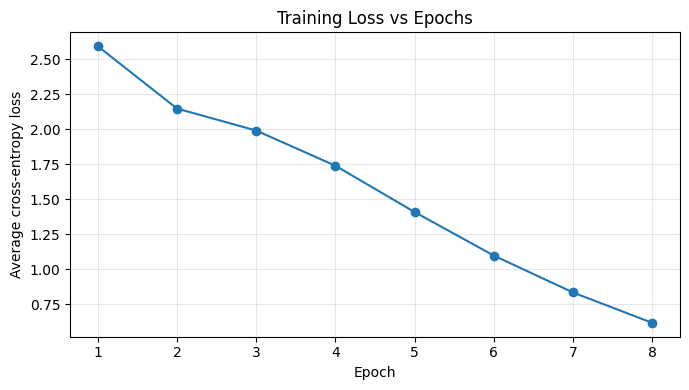

In [10]:
# Training loss vs epochs.
plt.figure(figsize=(7, 4))
plt.plot(range(1, EPOCHS + 1), epoch_losses, marker="o")
plt.title("Training Loss vs Epochs")
plt.xlabel("Epoch")
plt.ylabel("Average cross-entropy loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Part 4 — Sampling / Decoding

To generate text we run the model **autoregressively**: feed the prompt, predict one character, append it, and repeat. We keep only the last `seq_len` characters as context.

We implement all three decoding strategies with **one** unified generator, then call it in the three modes:

- **Greedy** — always take the `argmax` (deterministic).
- **Temperature** — divide logits by `T` before softmax, then sample. `T<1` sharpens (safer), `T>1` flattens (more random).
- **Top-k** — keep only the `k` highest-probability characters, renormalise, then sample.

In [11]:
@torch.no_grad()
def generate(model, prompt, max_new_tokens=300, mode="greedy",
             temperature=1.0, top_k=None, seed=1337):
    """Autoregressively generate text from a prompt.

    mode: "greedy" | "temperature" | "top_k"
    """
    set_seed(seed)          # fix RNG so stochastic modes are reproducible
    model.eval()

    ids = torch.tensor(encode(prompt), dtype=torch.long, device=device).unsqueeze(0)

    for _ in range(max_new_tokens):
        # Crop context to the last seq_len tokens (the model's window).
        ids_cond = ids[:, -model.seq_len:]
        logits = model(ids_cond)[:, -1, :]        # logits for the next char only

        if mode == "greedy":
            next_id = torch.argmax(logits, dim=-1, keepdim=True)
        else:
            # Temperature scaling (temperature == 1.0 leaves logits unchanged).
            logits = logits / temperature

            # Top-k filtering: mask out everything below the k-th largest logit.
            if mode == "top_k" and top_k is not None:
                vals, _ = torch.topk(logits, top_k)
                logits[logits < vals[:, [-1]]] = float("-inf")

            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)

        ids = torch.cat([ids, next_id], dim=1)

    return decode(ids[0].tolist())


PROMPT = "ROMEO:"

## 4.1 Greedy Decoding

Always pick the single most likely next character. Deterministic — the same prompt always gives the same output.

In [12]:
print(generate(model, PROMPT, max_new_tokens=300, mode="greedy"))

ROMEO:
I know tame to to tell thee whee whee who I am:
My name, dear saint, is hateful to myself,
Because it is en is en the envis mousion,
Who mo sindo eat sindo alreareasco asen,
Twou it is ale in ale is ther sun.
Be sing an.
I is mo mall tong oo bone ot ot oteast.
What me of thy do nar that
Tam, ale a 


## 4.2 Temperature Sampling

Sampling from the distribution after dividing logits by a temperature `T`. We try **three** temperatures with clearly different behaviour: a low, sharpening value; the neutral value; and a high, flattening value.

In [13]:
for T in [0.5, 1.0, 1.5]:
    print(f"================ temperature = {T} ================")
    print(generate(model, PROMPT, max_new_tokens=300,
                   mode="temperature", temperature=T))
    print()

================ temperature = 0.5 ================


ROMEO:
O:
By a ka kne
I know ame tot to to tell thee whee who I am:
My name, dear sar sainteful to myself,
Because it is en then emy the;
Had ent I I whill wer be wot.
Mon nore, tor bore, shat, nor shateateat,
Nor is nor sheaks is nor sall anvespeak the knd;
Here I I will am anos be wold ’tis ’tin tit not

================ temperature = 1.0 ================


ROMEO:
O:
By a ka ow tow thell theca rose
By any other word woull sword sme
So Romeo would, wo werear Romeould,
Re heat whin t thow athitlt thee woug:
Wtat to OMy Mond, a all my nameatear is?
Bewor sit itthe wor editleas e sheey sphes
Twou it ink is mysenelf, theirn nothe sphen tiotheres
To sparestwou thy

================ temperature = 1.5 ================


ROMEO:
O:
Shall I ome all ad, be I’ll thy re re nor name, bapt sher r my shed;
He I hou t, wis tof it tot,
unoot t f Romeo at why wheldeaithe ender I wheHld no I I hee.
T:
My sal namell to is ttame.
:
’n to love she inger shao but bescoest oesck and,
Her ar It is it noonem, aln busto mysO!
Bew she ter my 



## 4.3 Top-k Sampling

Restrict sampling to the `k` most likely characters at each step. We compare a **small** `k` (tight shortlist, safer) with a **large** `k` (wide pool, more diverse).

In [14]:
for k in [5, 20]:
    print(f"================ top-k = {k} ================")
    print(generate(model, PROMPT, max_new_tokens=300,
                   mode="top_k", top_k=k))
    print()

================ top-k = 5 ================


ROMEO:
O:
By a ka kne
I know ame
I tort it meouhy wo, dof thor ris ar m, shaind sill the envious my ady,
The remou faid thesineesem, she is e envioresstall lives my busick en’d gre but dole hest is do entus do hesco ent it it ent her es
To heink alen, in spheir my enkn ther sphes
Therelf thy tirnk thy nom

================ top-k = 20 ================


ROMEO:
O:
By a ka ow tow thell theca rose
By any other word woull sword sme
So Romeo would, wo werear Romeould,
Re heat whin t thow athitlt thee woug:
Wtat to OMy Mond, a all my nameatear is?
Bewor sit itthe wor editleas e sheey sphes
Twou it ink is mysenelf, theirn nothe sphen tiotheres
To sparestwou thy



# Part 5 — Short Analysis

**Greedy decoding** is deterministic: at each step it takes the single highest-probability character. On this model its output is the most **coherent** and closely tracks the training text, but it has no way to escape a high-probability rut, so it is prone to short **repetition loops** (e.g. doubled fragments such as *"to to tell thee"* or *"whee whee"*). It has essentially **zero diversity** — the same prompt always yields the same continuation.

**Temperature sampling** re-shapes the distribution before sampling. At a **low** temperature (`T = 0.5`) the distribution is sharpened, so output stays close to greedy: mostly coherent, low diversity. At `T = 1.0` the model samples from its true distribution — a good balance of coherence and variety. At a **high** temperature (`T = 1.5`) the distribution flattens, low-probability characters get picked far more often, and the text becomes the **most diverse but least coherent**, drifting into malformed words. Temperature is a smooth *coherence <-> diversity* dial.

**Top-k sampling** first throws away every character outside the `k` most likely, then samples from what remains. This keeps the randomness of sampling while cutting off the unlikely "tail" that produces nonsense. A **small `k` (5)** is a tight shortlist — safer and more coherent, with moderate variety. A **larger `k` (20)** admits many more candidates and behaves close to plain temperature-1.0 sampling — noticeably more diverse, with more errors.

**Conclusions**

- **Most coherent:** **greedy decoding** (closely followed by low-temperature / small-`k` sampling), because it always commits to high-probability characters — at the cost of repetition and no variety.
- **Most diverse:** **high-temperature sampling (`T = 1.5`)**, because flattening the distribution maximises the chance of picking unusual characters — at the cost of coherence. Large-`k` sampling is the next most diverse.
- **Best practical balance:** **top-k with a modest `k`** (or temperature near 1.0) — it preserves variety while top-k's tail-cutting keeps the output from degenerating into noise.